##  Autoregressive Hidden Markov Model (AR-HMM)

AR-HMM gives every hidden state its own autoregressive equation:

$$Inflation_t=c_{S_t}+\phi_{S_t}Inflation_{t-1}+error_t$$

For two states this means:

$$State\ 0: \quad Inflation_t=c_0+\phi_0 Inflation_{t-1}+error_t$$

$$State\ 1: \quad Inflation_t=c_1+\phi_1 Inflation_{t-1}+error_t$$

The state is unknown, so the final forecast combines both state-specific forecasts using predicted state probabilities.

**one-month-ahead forecast equation**

Before observing inflation in month $t$, the model calculates a forecast under every possible state:

$$Forecast_{t,s}=c_s+\phi_s Inflation_{t-1}$$

It then uses the predicted probability of each state:

$$\widehat{Inflation}_t=\sum_{s=0}^{1}P(S_t=s\mid Information_{t-1})(c_s+\phi_s Inflation_{t-1})$$

In [1]:
# Choose one: 'database' or 'csv'
DATA_SOURCE = 'database'

N_STATES = 2
TEST_START = '2017-01-01'

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

search_locations = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(path for path in search_locations if (path / 'README.md').exists())
CSV_PATH = PROJECT_ROOT / 'data' / 'processed' / 'US' / 'us_macro_2007_2023.csv'
print('Selected source:', DATA_SOURCE)

Selected source: database


**Load US CPI**

In [3]:
if DATA_SOURCE == 'database':
    from sqlalchemy import text

    sys.path.insert(0, str(PROJECT_ROOT))
    from modelling.config import get_sqlalchemy_engine

    engine = get_sqlalchemy_engine()
    query = text("""
        SELECT month_date, cpi_value
        FROM analytics.Monthly_Region_Wide_View
        WHERE region_code = 'US'
        ORDER BY month_date
    """)
    raw = pd.read_sql(query, engine, parse_dates=['month_date'])
    raw = raw.rename(columns={'month_date': 'Date', 'cpi_value': 'CPI'})
else:
    raw = pd.read_csv(
        CSV_PATH, usecols=['Date', 'CPIAUCSL'], parse_dates=['Date']
    ).rename(columns={'CPIAUCSL': 'CPI'})

raw = raw.sort_values('Date').drop_duplicates('Date').set_index('Date')
raw['CPI'] = pd.to_numeric(raw['CPI'], errors='coerce')
print('Rows:', len(raw))
print('Period:', raw.index.min().date(), 'to', raw.index.max().date())

Rows: 204
Period: 2007-01-01 to 2023-12-01


**Create monthly inflation, its lag, and the fixed split**

In [4]:
data = raw.copy()
data['Inflation_MoM'] = data['CPI'].pct_change(1, fill_method=None) * 100
data['Inflation_Lag1'] = data['Inflation_MoM'].shift(1)
model_data = data[['Inflation_MoM', 'Inflation_Lag1']].dropna().copy()

test_start = pd.Timestamp(TEST_START)
train = model_data.loc[model_data.index < test_start].copy()
test = model_data.loc[model_data.index >= test_start].copy()

if train.empty or test.empty:
    raise ValueError('TEST_START must leave observations in both periods.')

print('Training period:', train.index.min().date(), 'to', train.index.max().date())
print('Training months:', len(train))
print('Test period:    ', test.index.min().date(), 'to', test.index.max().date())
print('Test months:    ', len(test))

Training period: 2007-03-01 to 2016-12-01
Training months: 118
Test period:     2017-01-01 to 2023-12-01
Test months:     84


**Fit the AR(1) reference**

In [5]:
X_train_ar1 = sm.add_constant(train[['Inflation_Lag1']], has_constant='add')
ar1_model = sm.OLS(train['Inflation_MoM'], X_train_ar1).fit()
X_test_ar1 = sm.add_constant(test[['Inflation_Lag1']], has_constant='add')
test['Forecast_AR1'] = ar1_model.predict(X_test_ar1)

**Repeat the pure HMM reference**

In [6]:
np.random.seed(42)
hmm_model = sm.tsa.MarkovRegression(
    train['Inflation_MoM'],
    k_regimes=N_STATES,
    trend='c',
    switching_variance=False,
)
hmm_result = hmm_model.fit(
    disp=False, maxiter=1000, search_reps=20
)

hmm_means = np.array([
    hmm_result.params[f'const[{state}]'] for state in range(N_STATES)
])
hmm_variance = max(float(hmm_result.params['sigma2']), 1e-12)
hmm_transition = hmm_result.regime_transition[:, :, 0]
hmm_filtered_probability = (
    hmm_result.filtered_marginal_probabilities.iloc[-1].to_numpy()
)
hmm_forecasts = []

for actual_inflation in test['Inflation_MoM'].to_numpy():
    hmm_predicted_probability = hmm_transition @ hmm_filtered_probability
    hmm_forecasts.append(float(hmm_predicted_probability @ hmm_means))

    hmm_likelihood = (
        np.exp(
            -0.5 * (actual_inflation - hmm_means) ** 2 / hmm_variance
        )
        / np.sqrt(2 * np.pi * hmm_variance)
    )
    hmm_updated = hmm_predicted_probability * hmm_likelihood
    if hmm_updated.sum() > 0:
        hmm_filtered_probability = hmm_updated / hmm_updated.sum()
    else:
        hmm_filtered_probability = hmm_predicted_probability

test['Forecast_HMM'] = hmm_forecasts

c:\Users\zahra\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


**Fit the AR-HMM on training data**

In [7]:
np.random.seed(42)
arhmm_model = sm.tsa.MarkovRegression(
    train['Inflation_MoM'],
    k_regimes=N_STATES,
    trend='c',
    exog=train[['Inflation_Lag1']],
    switching_exog=True,
    switching_variance=False,
)
arhmm_result = arhmm_model.fit(
    disp=False, maxiter=2000, search_reps=30
)

print('AR-HMM converged:', arhmm_result.mle_retvals.get('converged', False))

c:\Users\zahra\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


AR-HMM converged: True


In [8]:
arhmm_constants = np.array([
    arhmm_result.params[f'const[{state}]'] for state in range(N_STATES)
])
arhmm_phis = np.array([
    arhmm_result.params[f'x1[{state}]'] for state in range(N_STATES)
])
arhmm_variance = max(float(arhmm_result.params['sigma2']), 1e-12)
arhmm_transition = arhmm_result.regime_transition[:, :, 0]

equation_table = pd.DataFrame({
    'Constant (c)': arhmm_constants,
    'Lag coefficient (phi)': arhmm_phis,
}, index=[f'State {state}' for state in range(N_STATES)])
equation_table

,Constant (c),Lag coefficient (phi)
State 0,0.111441,0.404761
State 1,-0.895064,1.031677


In [9]:
for state in range(N_STATES):
    print(
        f'State {state}: Inflation_t = {arhmm_constants[state]:.4f} '
        f'+ {arhmm_phis[state]:.4f} × Inflation_(t-1)'
    )

State 0: Inflation_t = 0.1114 + 0.4048 × Inflation_(t-1)
State 1: Inflation_t = -0.8951 + 1.0317 × Inflation_(t-1)


**AR-HMM transition probabilities**

In [10]:
arhmm_transition_table = pd.DataFrame(
    arhmm_transition.T,
    index=[f'From state {state}' for state in range(N_STATES)],
    columns=[f'To state {state}' for state in range(N_STATES)],
)
arhmm_transition_table.round(3)

,To state 0,To state 1
From state 0,0.986,0.014
From state 1,0.624,0.376


**Produce one-month-ahead AR-HMM forecasts**

In [11]:
arhmm_filtered_probability = (
    arhmm_result.filtered_marginal_probabilities.iloc[-1].to_numpy()
)
arhmm_forecasts = []
arhmm_predicted_probabilities = []

for actual_inflation, lagged_inflation in test[[
    'Inflation_MoM', 'Inflation_Lag1'
]].to_numpy():
    arhmm_predicted_probability = (
        arhmm_transition @ arhmm_filtered_probability
    )
    arhmm_predicted_probabilities.append(arhmm_predicted_probability.copy())

    state_forecasts = arhmm_constants + arhmm_phis * lagged_inflation
    arhmm_forecasts.append(
        float(arhmm_predicted_probability @ state_forecasts)
    )

    arhmm_likelihood = (
        np.exp(
            -0.5 * (actual_inflation - state_forecasts) ** 2
            / arhmm_variance
        )
        / np.sqrt(2 * np.pi * arhmm_variance)
    )
    arhmm_updated = arhmm_predicted_probability * arhmm_likelihood
    if arhmm_updated.sum() > 0:
        arhmm_filtered_probability = arhmm_updated / arhmm_updated.sum()
    else:
        arhmm_filtered_probability = arhmm_predicted_probability

test['Forecast_ARHMM'] = arhmm_forecasts
test[[
    'Inflation_MoM', 'Inflation_Lag1', 'Forecast_ARHMM'
]].head(10)

,Inflation_MoM,Inflation_Lag1,Forecast_ARHMM
Date,,,
2017-01-01,0.404308,0.252452,0.201594
2017-02-01,0.159266,0.404308,0.264410
2017-03-01,-0.046720,0.159266,0.162976
2017-04-01,0.123415,-0.046720,0.077779
2017-05-01,-0.077398,0.123415,0.148218
2017-06-01,0.065163,-0.077398,0.065089
2017-07-01,0.032765,0.065163,0.124122
2017-08-01,0.384863,0.032765,0.110718
2017-09-01,0.510639,0.384863,0.256366


**Compare all three models using test RMSE**

In [12]:
ar1_rmse = np.sqrt(np.mean(
    (test['Inflation_MoM'] - test['Forecast_AR1']) ** 2
))
hmm_rmse = np.sqrt(np.mean(
    (test['Inflation_MoM'] - test['Forecast_HMM']) ** 2
))
arhmm_rmse = np.sqrt(np.mean(
    (test['Inflation_MoM'] - test['Forecast_ARHMM']) ** 2
))

rmse_comparison = pd.DataFrame({
    'Test RMSE': [ar1_rmse, hmm_rmse, arhmm_rmse]
}, index=['AR(1)', 'HMM', 'AR-HMM'])
rmse_comparison.sort_values('Test RMSE')

,Test RMSE
AR(1),0.265153
AR-HMM,0.269457
HMM,0.331266


In [13]:
print(f'AR-HMM improvement over pure HMM: {hmm_rmse - arhmm_rmse:.4f}')

if arhmm_rmse < ar1_rmse:
    print(f'AR-HMM improved over AR(1) by {ar1_rmse - arhmm_rmse:.4f}.')
else:
    print(f'AR-HMM did not beat AR(1); it was worse by {arhmm_rmse - ar1_rmse:.4f}.')

AR-HMM improvement over pure HMM: 0.0618
AR-HMM did not beat AR(1); it was worse by 0.0043.


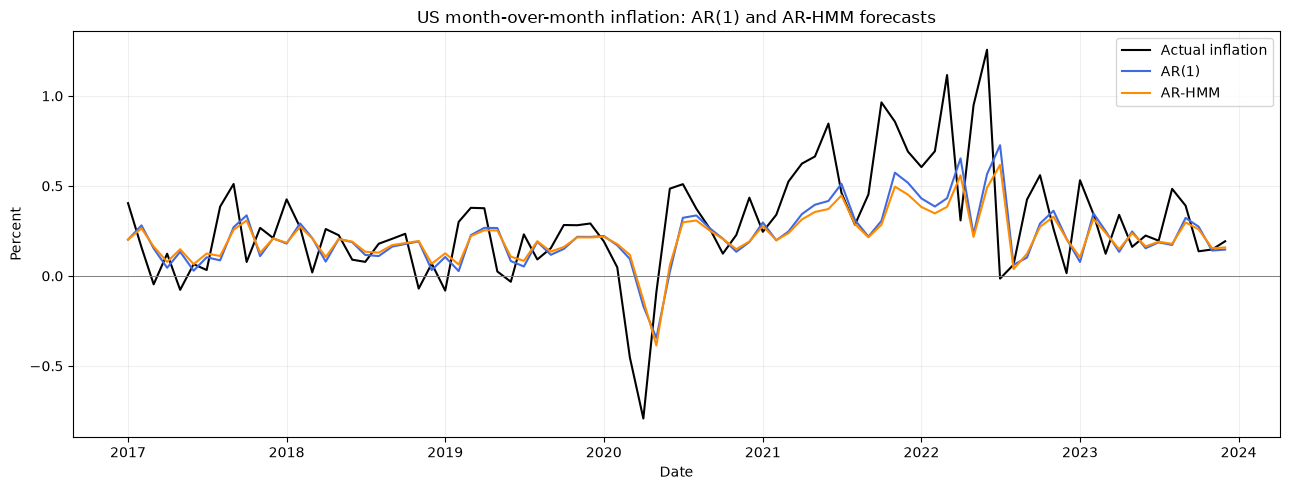

In [14]:
plt.figure(figsize=(13, 5))
plt.plot(test.index, test['Inflation_MoM'], label='Actual inflation', color='black')
plt.plot(test.index, test['Forecast_AR1'], label='AR(1)', color='royalblue')
plt.plot(test.index, test['Forecast_ARHMM'], label='AR-HMM', color='darkorange')
plt.axhline(0, color='gray', linewidth=0.7)
plt.title('US month-over-month inflation: AR(1) and AR-HMM forecasts')
plt.ylabel('Percent')
plt.xlabel('Date')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()